# Data Preparation

In [1]:
import torch
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import ast

import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.autonotebook import tqdm

from gctsvg.preprocessing import st, kidneycancer

/opt/conda/envs/ctSVG/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/opt/conda/envs/ctSVG/lib/python3.12/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/tmp/ipykernel_2475311/3006878544.py:12: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


Identify source and results directories

In [2]:
results_dir = Path("hgctsvg_output")
project_name = "Human Kidney Cancer Interface"

project_files_dir = results_dir / project_name
project_files_dir.mkdir(parents=True, exist_ok=True)

In [3]:
decomp_folder = Path("Spotiphy_Result") / project_name

Load deconvolution results and spatial transcriptomics data.

Spatial transcriptomics data contains spot ids and spot locations, which are requirements for creating hyperedges.

In [4]:
adata_decomp = sc.read_h5ad(decomp_folder / "ST_decomposition.h5ad")
adata_st = sc.read_h5ad(decomp_folder / "Human Kidney Cancer Interface.h5ad")

Load *n_cell_df.csv*.  This file contains nucleuse indices, nucleus centers, and cell counts per spot.

Note: Based on the information provided by *n_cell_df.csv*, Spotiphy predicts the number of cells of each type in a spot. However, identifying which of the cells are of the given types is a random guess.

In [5]:
# Cell df contains nucleus indices, nucleus centers, and cell counts per spots
cell_df = pd.read_csv(decomp_folder / "segmentation" / "n_cell_df.csv",
                     index_col=0)

Load segmentation results.

Segmentation results contain cells' membership to spots, tissue location, and cell boundaries, which are important in visualization.

In [6]:
# Load segmentation boundary
segmentation_boundary = np.load(decomp_folder / "segmentation" / "segmentation_boundary.npy", allow_pickle=True)
segmentation_boundary.shape

(60995, 32, 2)

In [7]:
# Extract nucleus centers and cell boundaries from the segmentation results.
cell_centers = np.empty((adata_decomp.n_obs, 2), dtype=float)
cell_boundaries = np.empty((adata_decomp.n_obs,32,2), dtype=float)

for i in range(adata_st.n_obs):
    cell_count = cell_df['cell_count'][i]
    if cell_count == 0:
        continue
    nucleus_indices = ast.literal_eval(cell_df['Nucleus indices'][i])
    nucleus_centers = ast.literal_eval(cell_df['Nucleus centers'][i])
    nucleus_centers = np.array(nucleus_centers)
    cell_boundary_x = segmentation_boundary[nucleus_indices][:,:,0]
    cell_boundary_y = segmentation_boundary[nucleus_indices][:,:,1]
    
    # nucleus_centers_df = pd.DataFrame(nucleus_centers, columns=["nucleus_x", "nucleus_y"])

    cell_indexes = adata_decomp[adata_decomp.obs["spot_name"] == adata_st.obs_names[i]].obs_names
    cell_centers[cell_indexes.values.astype(int)] = nucleus_centers
    cell_boundaries[cell_indexes.values.astype(int)] = segmentation_boundary[nucleus_indices]
    # print(cell_boundary_x)
    # cell_topology.loc[cell_indexes, "boundary_x"] = cell_boundary_x
    # cell_topology.loc[cell_indexes, "boundary_y"] = cell_boundary_y

In [8]:
adata_decomp.obsm['cell_nucleus'] = cell_centers
adata_decomp.obsm['cell_boundaries'] = cell_boundaries
adata_decomp.obsm['cell_nucleus'].shape, adata_decomp.obsm['cell_boundaries'].shape

((22431, 2), (22431, 32, 2))

Assign the nucleus location as the location of each cell. 

Squidpy's plotting functions require the input data to have the spatial metadata ` adata_decomp.obsm['spatial'] `.

In [9]:
adata_decomp.obsm['spatial'] = adata_decomp.obsm['cell_nucleus']

Type list is an array of all cell types in the tissue, sorted alphabetically.

Cell type mapping is a mapping of cell type names (string) to their position in type list (integer). Cell type mapping will be used in preparing datasets for the ML pipeline.

In [10]:
type_list, cell_type_mapping = kidneycancer.create_cell_type_mapping(adata_decomp)
type_list, cell_type_mapping

(['B-cell',
  'EC',
  'Epi_PT',
  'Epi_non-PT',
  'Fibro',
  'Mast',
  'Myeloid',
  'NK',
  'Plasma',
  'RCC',
  'T-cell',
  'pDC'],
 {'B-cell': 0,
  'EC': 1,
  'Epi_PT': 2,
  'Epi_non-PT': 3,
  'Fibro': 4,
  'Mast': 5,
  'Myeloid': 6,
  'NK': 7,
  'Plasma': 8,
  'RCC': 9,
  'T-cell': 10,
  'pDC': 11})

Visualize distribution of each cell type within the tissue.

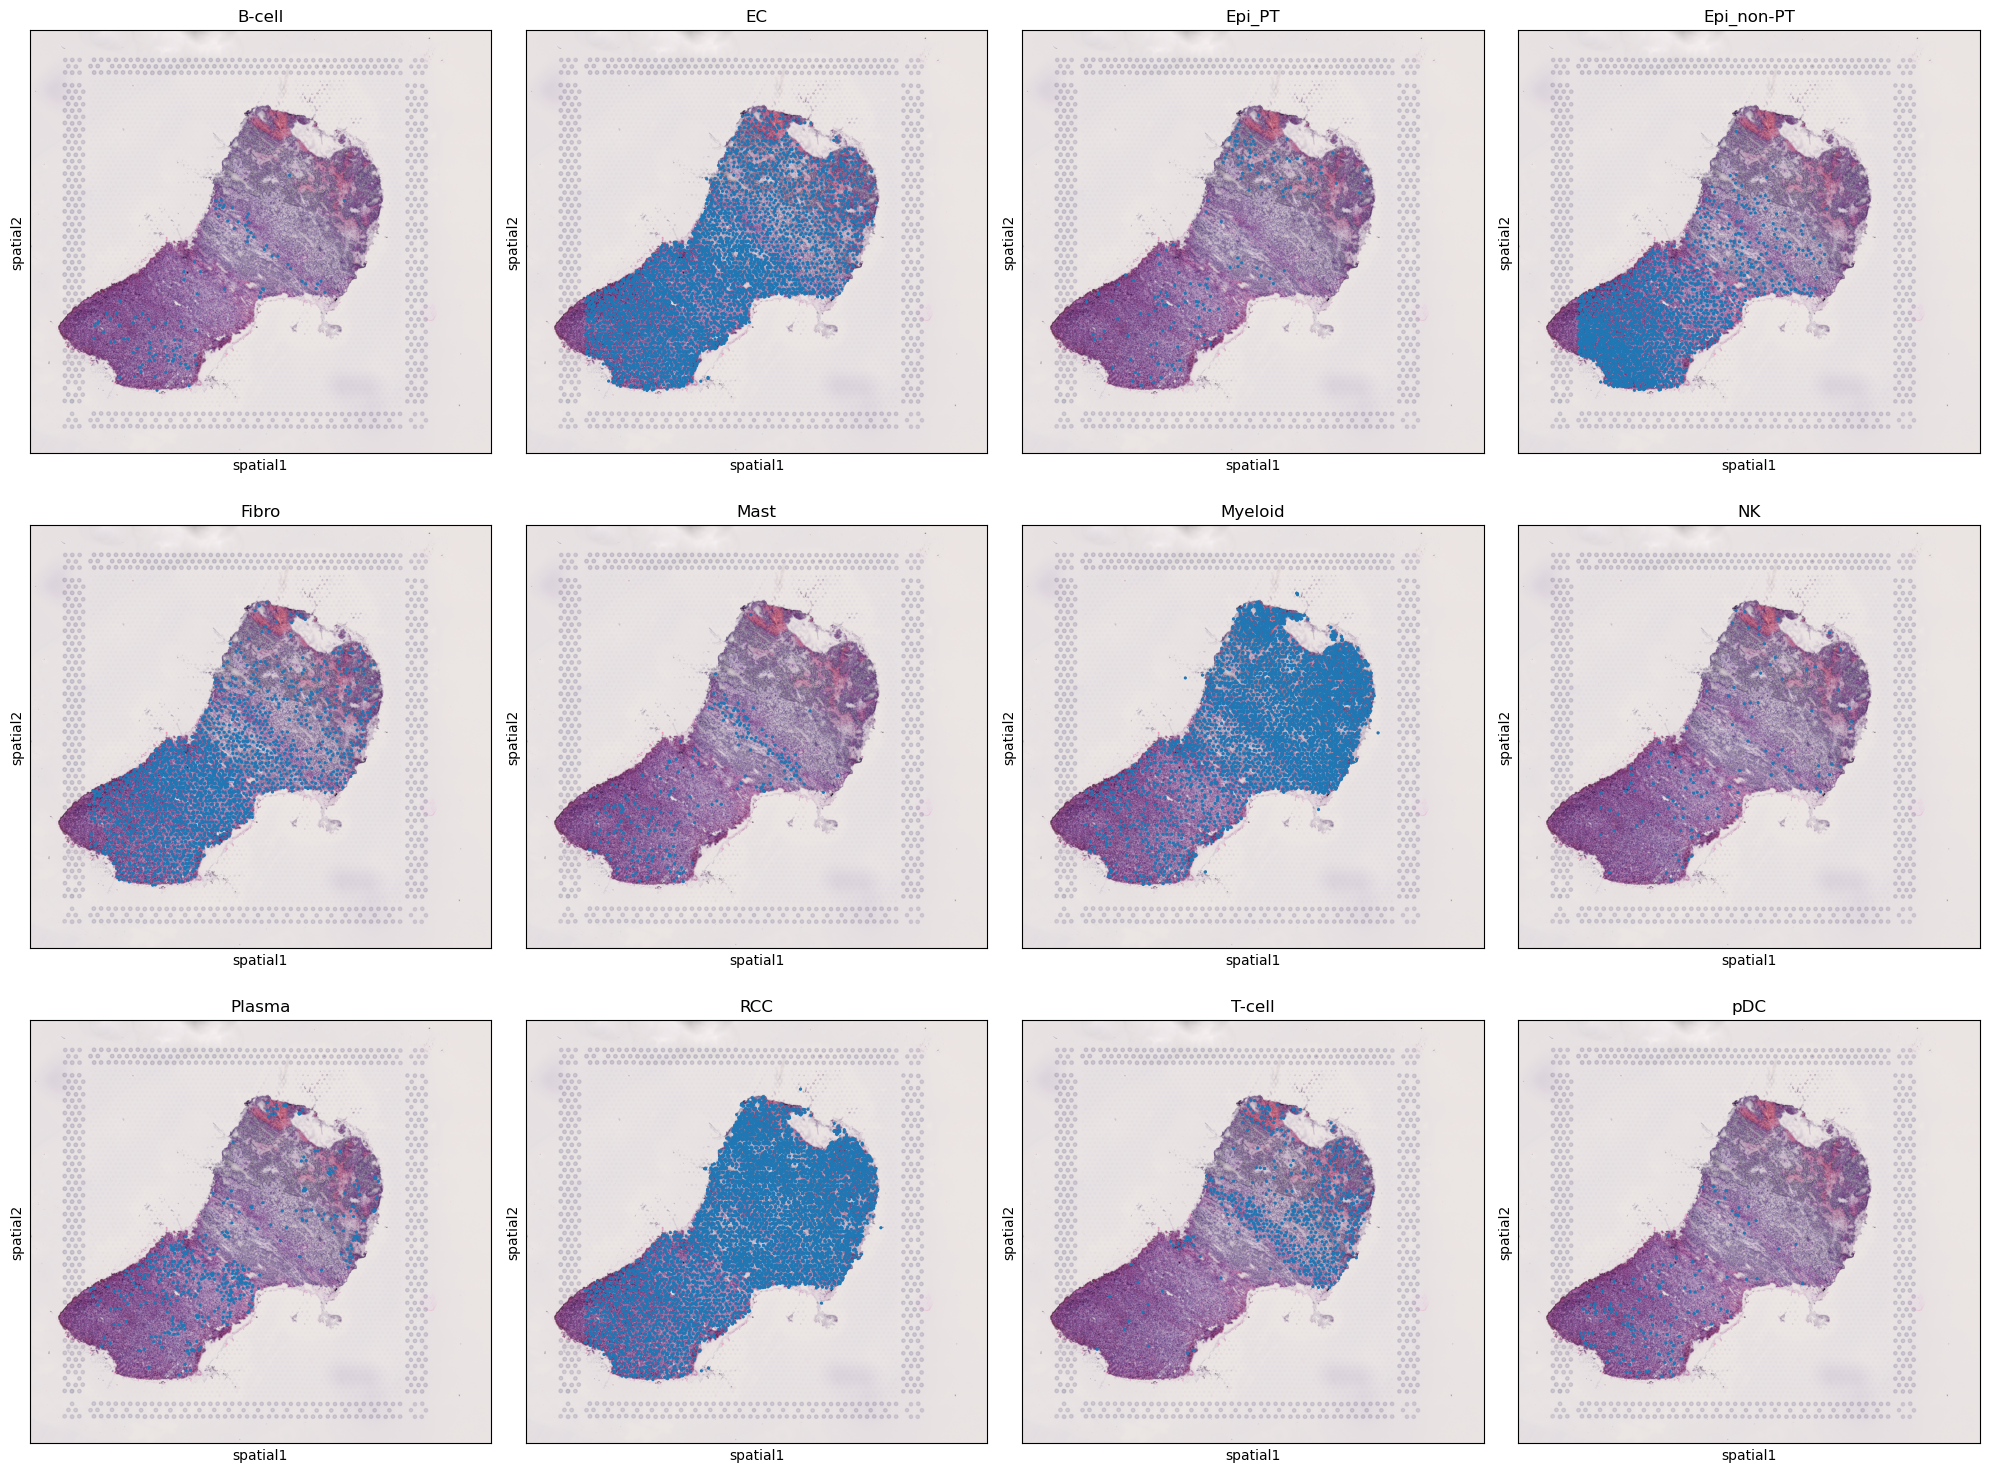

In [11]:
n_cell_types = len(type_list)
n_rows = 3
n_cols = n_cell_types//n_rows
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(20,15))

for i, cell_type in zip(range(n_cell_types), type_list):
    adata_celltype = adata_decomp[adata_decomp.obs['cell_type'] == cell_type].copy()
    sq.pl.spatial_scatter(
        adata_celltype,
        # adata_decomp[adata_decomp.obs['cell_type'] == cell_type],
        color="cell_type", # or a gene name
        ax=axes[i // n_cols][i % n_cols],
        title=cell_type,
        legend_loc=None
    )
plt.tight_layout()
plt.show()

Preprocess original and decomposed ST data.

In [12]:
n_top_genes = 3000
sc.pp.log1p(adata_decomp)
sc.pp.log1p(adata_st)
sc.pp.highly_variable_genes(adata_decomp, n_top_genes=n_top_genes)
sc.pp.highly_variable_genes(adata_st, n_top_genes=n_top_genes)

In [13]:
st_hvgs = adata_st.var[adata_st.var["highly_variable"]].index
decomp_hvgs = adata_decomp.var[adata_decomp.var["highly_variable"]].index

In [14]:
common_hvgs = decomp_hvgs.intersection(st_hvgs)

In [15]:
adata_st = adata_st[:, common_hvgs.values]
adata_decomp = adata_decomp[:,decomp_hvgs.values]

In [16]:
common_hvgs.shape

(666,)

In [17]:
from gctsvg.data import STHypergraphData

cell_feats, hyperedge_feats, cell_to_spot_id, cell_type, hyperedge_index, incidence_matrix, n_cell_types, n_spots = kidneycancer.create_hypergraph_data(adata_decomp, adata_st, num_neighbor_spots=7)

hgdata = STHypergraphData(cell_feats,
                          hyperedge_feats,
                          cell_to_spot_id,
                          cell_type,
                          hyperedge_index,
                          incidence_matrix,
                          n_cell_types,
                          n_spots)

hgdata.save(project_files_dir)

In [18]:
adata_st.obs

,in_tissue,array_row,array_col,sample,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,mt_frac,donor_id,region
spot_id,,,,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,1,50,102,6800STDY12499411,4778,8.471987,14815.0,9.603463,27.046912,35.227810,44.414445,56.179548,0.099426,PD47171,g
6800STDY12499411_AAACACCAATAACTGC-1,1,59,19,6800STDY12499411,1536,7.337588,2822.0,7.945555,27.250177,36.463501,46.172927,63.288448,0.105245,PD47171,g
6800STDY12499411_AAACATGGTGAGAGGA-1,1,62,0,6800STDY12499411,2243,7.716015,4582.0,8.430109,28.000873,35.050196,44.107377,59.340899,0.165430,PD47171,g
6800STDY12499411_AAACCGGGTAGGTACC-1,1,42,28,6800STDY12499411,2555,7.846199,4903.0,8.497807,19.620640,28.696716,38.894554,53.885376,0.044463,PD47171,g
6800STDY12499411_AAACCGTTCGTCCAGG-1,1,52,42,6800STDY12499411,1277,7.153052,2113.0,7.656337,22.432560,32.465689,43.965925,63.227638,0.034548,PD47171,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,1,24,64,6800STDY12499411,3235,8.082093,8386.0,9.034438,25.518722,36.358216,46.255664,59.372764,0.061770,PD47171,g
6800STDY12499411_TTGTTGTGTGTCAAGA-1,1,31,77,6800STDY12499411,4374,8.383662,12266.0,9.414668,22.215881,31.664764,41.415294,54.345345,0.036116,PD47171,g
6800STDY12499411_TTGTTTCACATCCAGG-1,1,58,42,6800STDY12499411,1328,7.192182,2317.0,7.748460,23.910229,34.570565,45.576176,64.264135,0.015537,PD47171,g


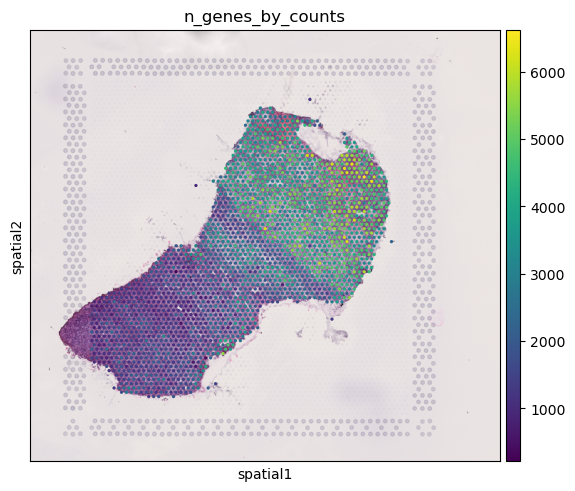

In [19]:
sq.pl.spatial_scatter(
        adata_st,
        # adata_decomp[adata_decomp.obs['cell_type'] == cell_type],
        color="n_genes_by_counts", # or a gene name
        title="n_genes_by_counts",
        legend_loc=None
)

In [20]:
adata_decomp.n_obs

22431

In [21]:
x = torch.tensor([[0,1,0,0,0],[0,0,0,1,0],[1,1,0,1,0]])

In [22]:
x.any(dim=1).nonzero(as_tuple=True)[0]

tensor([0, 1, 2])

In [23]:
adata_decomp.n_vars

3000

In [24]:
# save adata_st
adata_st.write_h5ad(project_files_dir / "ST_init.h5ad")

# save adata_decomp
adata_decomp.write_h5ad(project_files_dir / "ST_decomposition.h5ad")

# save type list
typelist_np = np.array(type_list, dtype=str)
np.savetxt(project_files_dir / 'cell_types.txt',
           typelist_np,
           fmt='%s',
           delimiter='\n')

# HGCTSVG Pipeline

For each step of the pipeline, run the following commands:

## I. Embedding Learning

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 python hgctsvg.py train-embedder --project "Human Kidney Cancer Interface" \
--model.input-dim 3000 --model.embedding-dim 200 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
python hgctsvg.py train-embedder --project "Human Kidney Cancer Interface" \
--model.input-dim 3000 --model.embedding-dim 200 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## II. Embedding Generation

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 python hgctsvg.py make-embedding --project "Human Kidney Cancer Interface" \
--model.input-dim 3000 --model.embedding-dim 200 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
python hgctsvg.py make-embedding --project "Human Kidney Cancer Interface" \
--model.input-dim 3000 --model.embedding-dim 200 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## III. Spatial Domain Identification

```bash
python hgctsvg.py compute-spatial-domains --project "Human Kidney Cancer Interface" 
```

## IV. Cell-type Specific Domain Identification

```bash
python hgctsvg.py compute-celltype-spatial-domains --project "Human Kidney Cancer Interface" \
--data.cell-type-key "cell_type"
```

## V. Classifier Training

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 python hgctsvg.py train-classifier --project "Human Kidney Cancer Interface" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
```

```bash
# Using CPU
python hgctsvg.py train-classifier --project "Human Kidney Cancer Interface" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cpu
```

## VI. Spatial Metagene Computation

### A. 

### B. 

In [41]:
adata_st_clusters = sc.read_h5ad(project_files_dir / "clustering" / "ST_init.h5ad")
adata_st_clusters

AnnData object with n_obs × n_vars = 2048 × 666
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'leiden'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'leiden', 'log1p', 'neighbors', 'sample_colors', 'spatial'
    obsm: 'embedding', 'spatial'
    obsp: 'connectivities', 'distances'

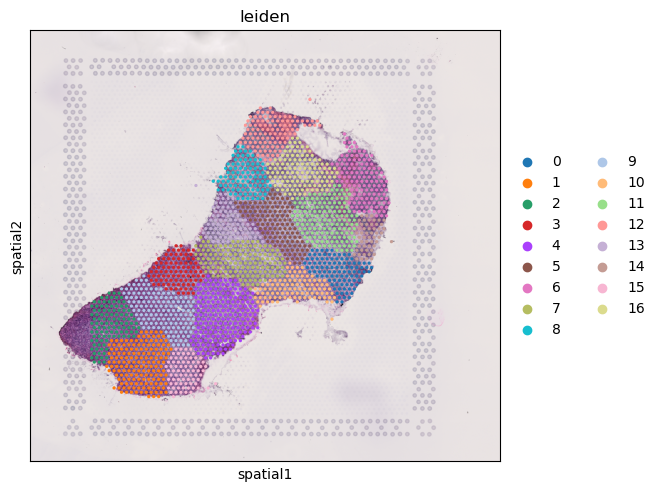

In [42]:
sq.pl.spatial_scatter(adata_st, spatial_key='spatial', color='leiden')

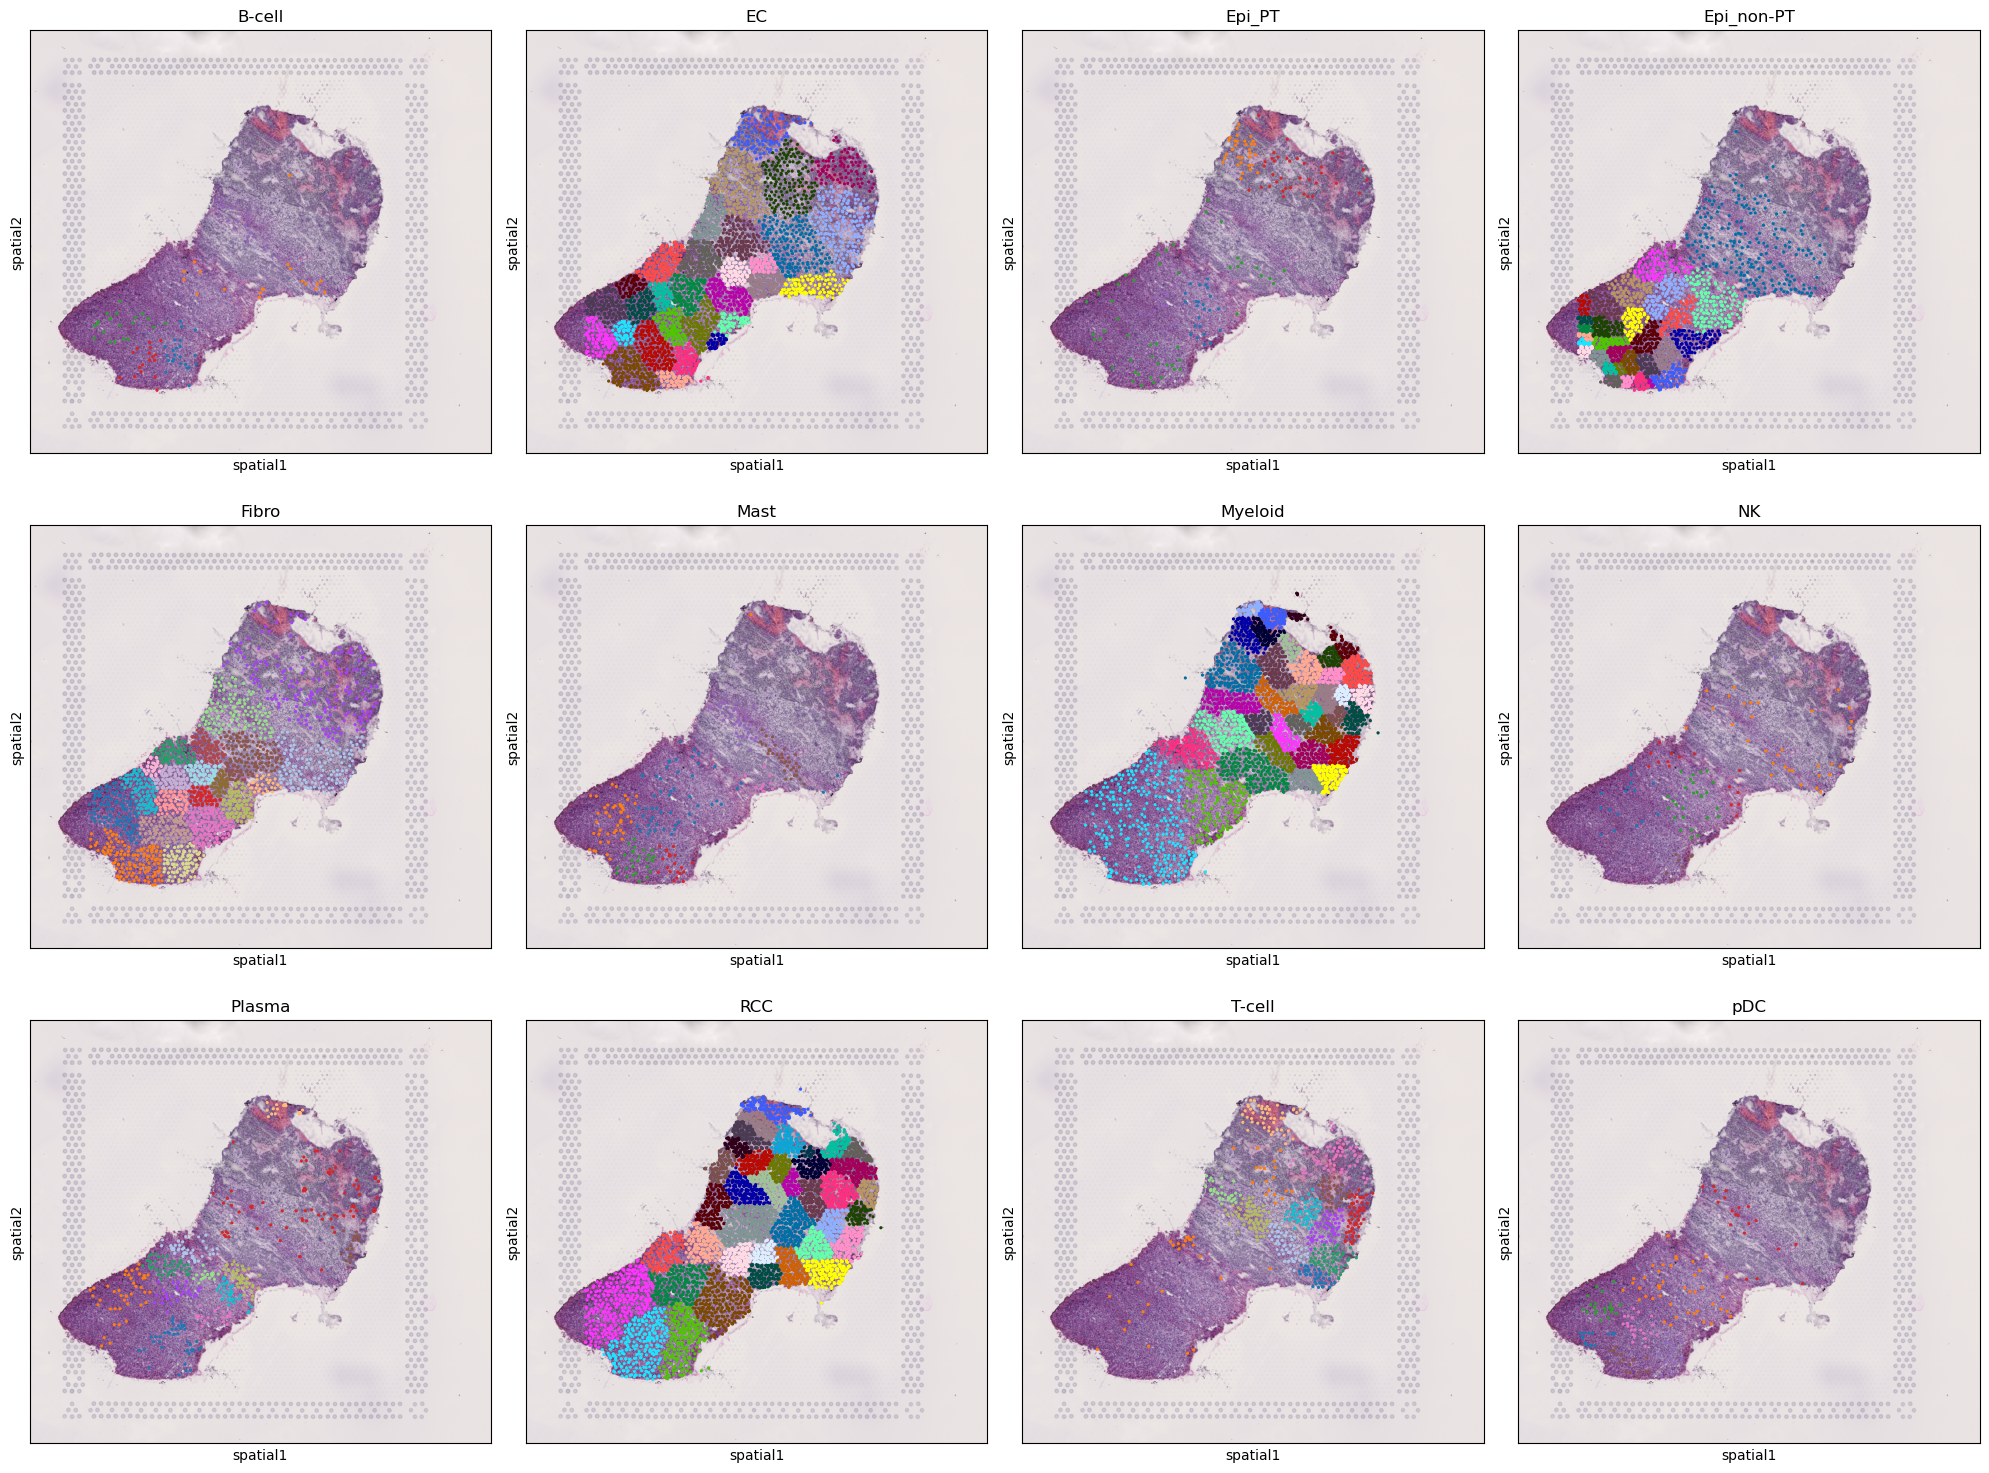

In [43]:
n_cell_types = len(type_list)
n_rows = 3
n_cols = n_cell_types // n_rows
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(20,15))

adata_celltypes = []
for i, cell_type in zip(range(n_cell_types), type_list):
    adata_celltype = sc.read_h5ad(project_files_dir / "clustering" / f"ST_{cell_type}.h5ad")
    # np_clusters = adata_celltype.obs["leiden"].to_numpy().astype("int")
    
    sq.pl.spatial_scatter(
        adata_celltype,
        # adata_decomp[adata_decomp.obs['cell_type'] == cell_type],
        color="leiden", # or a gene name
        ax=axes[i // n_cols][i % n_cols],
        title=cell_type,
        legend_loc=None
    )
    adata_celltypes.append(adata_celltype)

plt.tight_layout()
plt.show()

In [58]:
adata_celltype.obs['leiden'].to_numpy(dtype=int)

array([0, 0, 1, 1, 2, 3, 0, 1, 3, 1, 1, 4, 1, 1, 2, 4, 2, 5, 2, 6, 5, 1,
       3, 2, 1, 1, 1, 2, 5, 3, 1, 1, 3, 1, 6, 2, 1, 1, 0, 0, 0, 0, 0, 1,
       6, 4, 5, 5, 5, 1, 6, 2, 3, 2, 5, 3, 1, 1, 1, 1, 0, 3, 5, 6, 2, 1,
       3, 1, 3, 0, 2, 6, 3, 5, 4, 4, 5, 2, 2, 6, 6, 4, 2, 3, 6, 4, 3, 6,
       6, 2, 6, 1, 1, 4, 1, 6, 4, 6, 2, 1, 1, 0, 0, 0, 3, 4, 6, 5, 5, 6,
       4, 1, 4, 2, 1, 5, 6, 1, 1, 4, 4, 4, 3, 1, 4, 1, 3, 5, 0, 3, 6, 2,
       2, 2, 6, 1, 3, 3, 4, 4, 1, 6, 6, 2, 2, 5, 1, 1, 5, 4, 1, 3, 0, 1,
       1, 5, 1, 6])